# Week 3 — Advanced Data Analysis and Visualization in Logistics

This notebook explores the real processed Olist data created in Week 2. It calculates central tendency, spread, delivery KPIs, correlations and freight patterns, then creates charts with clear operational purposes.

Install: `python -m pip install pandas numpy matplotlib seaborn scipy`. Run Week 2 first. Outputs are saved under `reports/week3_visualizations`.

In [3]:
!python -m pip install --upgrade pip


In [4]:
!python -m pip install pandas numpy matplotlib seaborn plotly scikit-learn

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 162.9 kB/s eta 0:00:57
   -- -------------------

In [5]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
def root_dir():
    for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]:
        if (p/"data"/"processed"/"orders_preprocessed.csv").exists(): return p
    raise FileNotFoundError("Run Week 2 first.")
ROOT=root_dir(); PROC=ROOT/"data"/"processed"; REPORTS=ROOT/"reports"
CHARTS=REPORTS/"week3_visualizations"; CHARTS.mkdir(parents=True,exist_ok=True)
orders=pd.read_csv(PROC/"orders_preprocessed.csv")
items=pd.read_csv(PROC/"logistics_items_analysis.csv")
for c in ["order_purchase_timestamp","order_delivered_customer_date","order_estimated_delivery_date"]:
    orders[c]=pd.to_datetime(orders[c],errors="coerce")
delivered=orders[orders["actual_delivery_days"].notna()].copy()
known=orders[orders["delivery_result"].isin(["On time","Late"])].copy()
print("Orders:",len(orders),"delivered with duration:",len(delivered),"known outcomes:",len(known))

Orders: 99441 delivered with duration: 96476 known outcomes: 96476


## 1. Dataset variables and analysis grain

The order-level table is used for delivery duration and reliability. The item-level table is used for freight and product category analysis.

| Variable | Meaning | Business question |
|---|---|---|
| Purchase timestamp | When customer placed order | When does demand peak? |
| Actual delivery days | Purchase to customer delivery | How long does delivery take? |
| Delay days | Actual minus estimated date | How reliable is the promise? |
| Delivery result | On time, Late, Unknown | What share is late? |
| Item price / freight | Item-level amounts | What are freight patterns? |
| Product category | Product group | Do charges vary by category? |

Mean is sensitive to extreme delays; median is more robust. Reporting both helps describe a skewed delivery distribution.

In [6]:
metrics=["actual_delivery_days","estimated_delivery_days","delivery_delay_days"]
desc=orders[metrics].describe(percentiles=[.25,.5,.75,.9,.95]).T
display(desc); desc.to_csv(REPORTS/"week3_descriptive_statistics.csv")
x=delivered.actual_delivery_days.dropna()
stats=pd.Series({"count":x.count(),"mean":x.mean(),"median":x.median(),
 "std":x.std(),"q1":x.quantile(.25),"q3":x.quantile(.75),
 "iqr":x.quantile(.75)-x.quantile(.25),"p90":x.quantile(.90),"p95":x.quantile(.95)})
display(stats); stats.to_csv(REPORTS/"week3_delivery_statistics.csv")

,count,mean,std,min,25%,50%,75%,90%,95%,max
actual_delivery_days,96476.0,12.558702,9.546530,0.533414,6.766403,10.217755,15.720327,23.097604,29.276016,209.628611
estimated_delivery_days,99441.0,23.767650,8.832371,1.648993,18.331690,23.240370,28.424861,34.322049,38.484340,155.135463
delivery_delay_days,96476.0,-11.179120,10.186113,-146.016123,-16.244384,-11.948941,-6.390000,-1.137517,3.818458,188.975081


count     96476.000000
mean         12.558702
median       10.217755
std           9.546530
q1            6.766403
q3           15.720327
iqr           8.953924
p90          23.097604
p95          29.276016
dtype: float64

## 2. Delivery performance KPI

The denominator includes only known outcomes (On time + Late). Unknown orders are shown separately. This avoids incorrectly treating undelivered orders as on-time or late.

\[
On\ time\ rate = 
rac{On\ time}{On\ time + Late} \times 100
\]

In [7]:
counts=orders.delivery_result.value_counts(dropna=False)
on_time=known.delivery_result.eq("On time").mean()*100 if len(known) else np.nan
late=known.delivery_result.eq("Late").mean()*100 if len(known) else np.nan
display(counts)
kpi=pd.Series({"all_orders":len(orders),"known_outcomes":len(known),
 "unknown_outcomes":int(orders.delivery_result.eq("Unknown").sum()),
 "on_time_rate_percent":on_time,"late_rate_percent":late})
display(kpi); kpi.to_csv(REPORTS/"week3_kpis.csv")

delivery_result
On time    88649
Late        7827
Unknown     2965
Name: count, dtype: int64

all_orders              99441.000000
known_outcomes          96476.000000
unknown_outcomes         2965.000000
on_time_rate_percent       91.887101
late_rate_percent           8.112899
dtype: float64

## 3. Monthly order volume — line chart

A line chart suits ordered time data and helps identify demand peaks. Logistics teams can compare peak periods with staffing and carrier capacity. Check the date coverage: a partial final year should not be compared with a complete year.

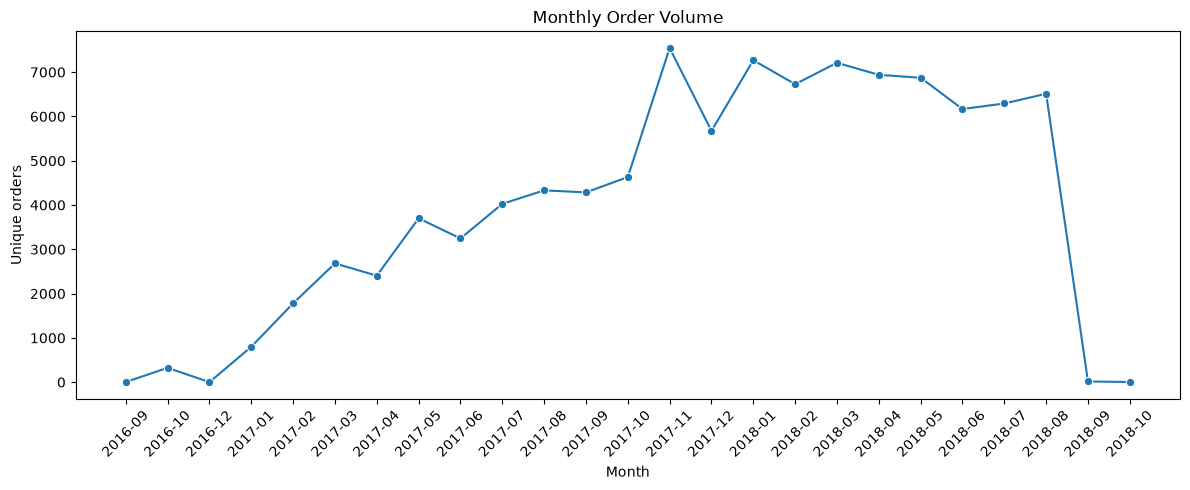

In [8]:
monthly=(orders.dropna(subset=["order_purchase_timestamp"])
 .assign(month=lambda z:z.order_purchase_timestamp.dt.to_period("M").astype(str))
 .groupby("month").order_id.nunique().reset_index(name="orders"))
plt.figure(figsize=(12,5)); sns.lineplot(data=monthly,x="month",y="orders",marker="o")
plt.title("Monthly Order Volume"); plt.xlabel("Month"); plt.ylabel("Unique orders")
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(CHARTS/"01_monthly_order_volume.png",dpi=160); plt.show()
monthly.to_csv(REPORTS/"week3_monthly_volume.csv",index=False)

## 4. Actual delivery time — histogram

A histogram shows concentration, skew and the slow tail. If mean is much higher than median, a smaller group of very delayed orders may be pulling the average upward. This chart includes only delivered orders with a valid delivery duration.

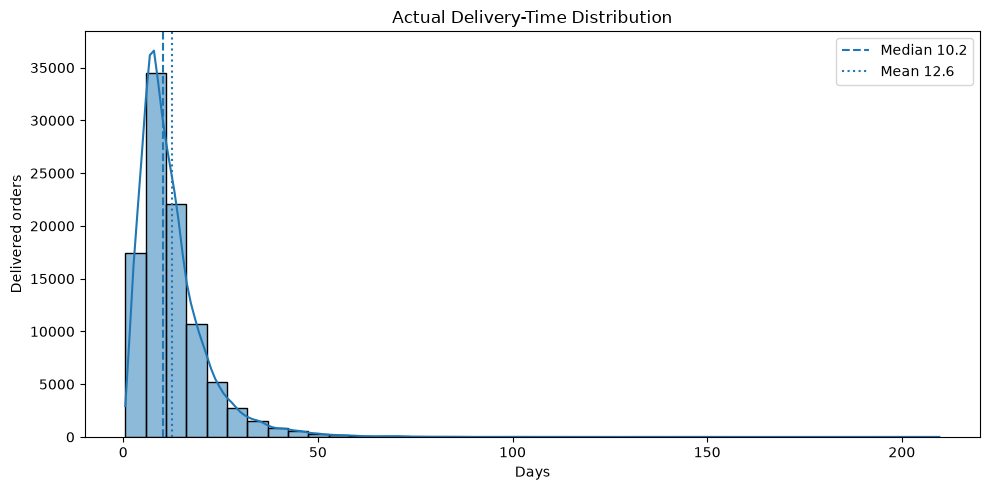

In [9]:
plt.figure(figsize=(10,5)); sns.histplot(delivered,x="actual_delivery_days",bins=40,kde=True)
plt.axvline(x.median(),ls="--",label=f"Median {x.median():.1f}")
plt.axvline(x.mean(),ls=":",label=f"Mean {x.mean():.1f}")
plt.title("Actual Delivery-Time Distribution"); plt.xlabel("Days"); plt.ylabel("Delivered orders")
plt.legend(); plt.tight_layout(); plt.savefig(CHARTS/"02_delivery_distribution.png",dpi=160); plt.show()

## 5. Delivery outcome — bar chart

A bar chart compares the number of known On-time and Late orders. Report the rates and denominator as well as counts, because counts are affected by total order volume. Unknown results are excluded from this chart and shown separately in the KPI output.

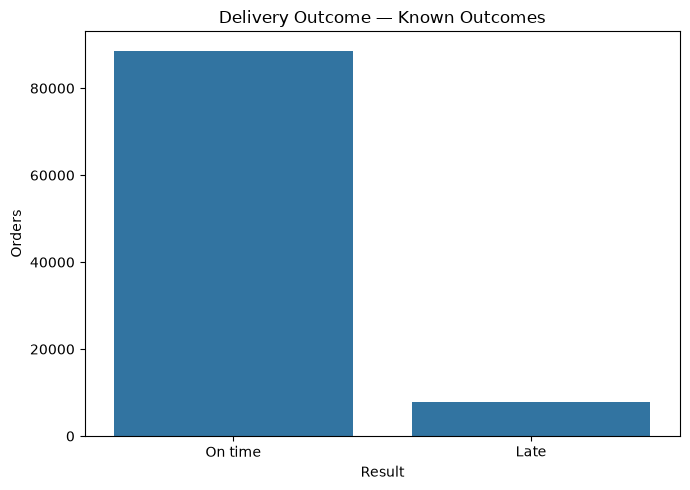

In [10]:
out=known.delivery_result.value_counts().rename_axis("result").reset_index(name="orders")
plt.figure(figsize=(7,5)); sns.barplot(data=out,x="result",y="orders")
plt.title("Delivery Outcome — Known Outcomes"); plt.xlabel("Result"); plt.ylabel("Orders")
plt.tight_layout(); plt.savefig(CHARTS/"03_delivery_outcomes.png",dpi=160); plt.show()

## 6. Delay distribution — boxplot

A boxplot summarizes median, quartiles and potential extremes. Negative delay means early delivery; positive delay means late delivery. Investigate extreme late cases instead of automatically removing them.

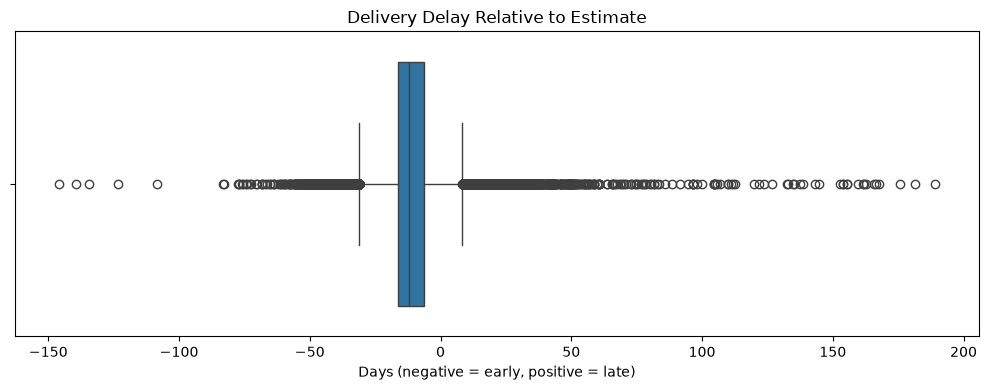

In [11]:
delay=orders.delivery_delay_days.dropna()
plt.figure(figsize=(10,4)); sns.boxplot(x=delay)
plt.title("Delivery Delay Relative to Estimate")
plt.xlabel("Days (negative = early, positive = late)")
plt.tight_layout(); plt.savefig(CHARTS/"04_delay_boxplot.png",dpi=160); plt.show()

## 7. Correlation heatmap

Spearman correlation measures monotonic association and is less dependent on normality than Pearson correlation. Values range from -1 to +1. Correlation is not causation. Actual duration, estimated duration and delay are mathematically related, so their correlation should be interpreted carefully.

,actual_delivery_days,estimated_delivery_days,delivery_delay_days
actual_delivery_days,1.000000,0.522157,0.311191
estimated_delivery_days,0.522157,1.000000,-0.567563
delivery_delay_days,0.311191,-0.567563,1.000000


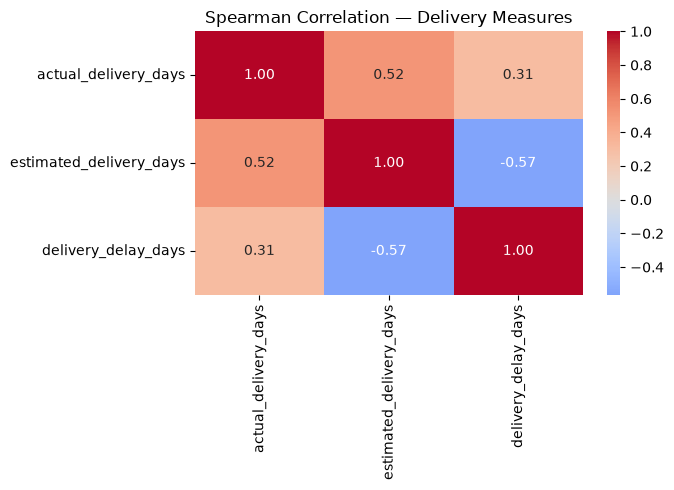

In [12]:
corr=orders[metrics].corr(method="spearman")
display(corr); corr.to_csv(REPORTS/"week3_spearman_correlation.csv")
plt.figure(figsize=(7,5)); sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,fmt=".2f")
plt.title("Spearman Correlation — Delivery Measures")
plt.tight_layout(); plt.savefig(CHARTS/"05_correlation_heatmap.png",dpi=160); plt.show()

## 8. Freight and category analysis

The freight histogram shows the distribution of shipping charges per item. The price-versus-freight scatterplot explores whether higher-priced items tend to have higher freight charges. Category comparisons use median freight and a minimum group size of 30 items to avoid unstable rankings. Freight is not the same as total logistics cost.

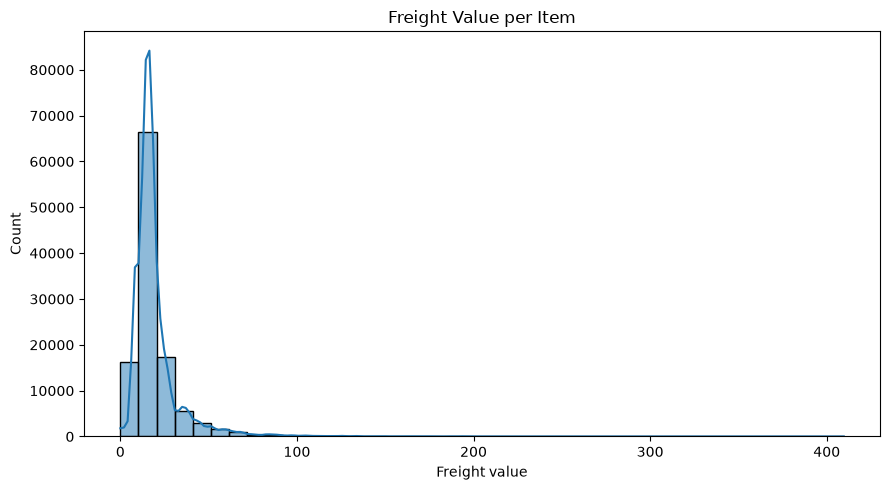

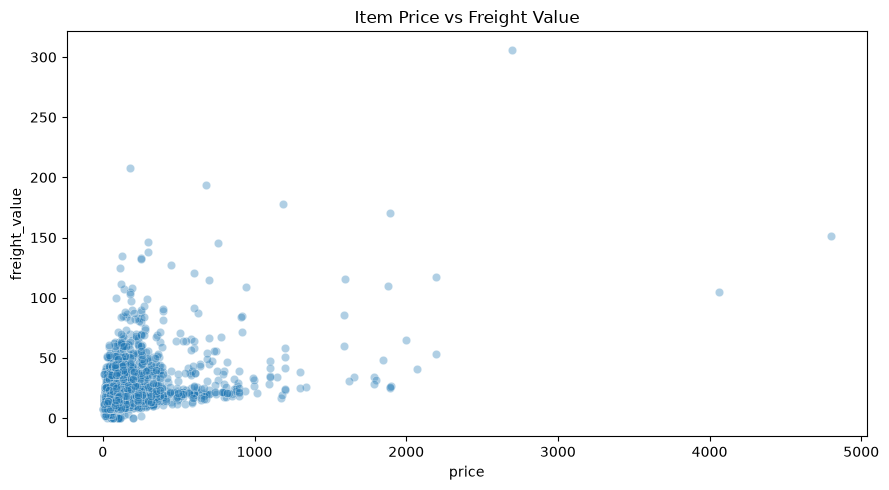

Spearman price/freight: SignificanceResult(statistic=np.float64(0.434190324041091), pvalue=np.float64(0.0))


,product_category_name_english,item_count,median_freight
0,computers,203,41.55
1,furniture_mattress_and_upholstery,38,38.97
2,furniture_bedroom,109,38.11
3,home_appliances_2,238,36.23
4,office_furniture,1691,34.18
5,kitchen_dining_laundry_garden_furniture,281,31.10
6,small_appliances_home_oven_and_coffee,76,28.98
7,furniture_living_room,503,26.72
8,agro_industry_and_commerce,212,23.68
9,industry_commerce_and_business,268,23.09


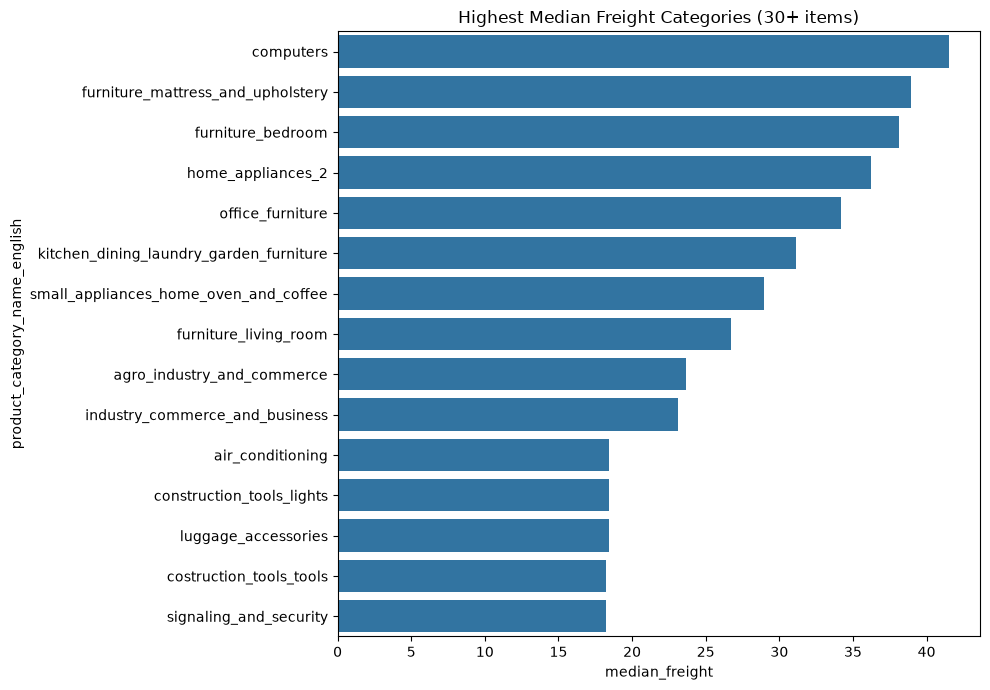

In [13]:
for c in ["price","freight_value"]: items[c]=pd.to_numeric(items[c],errors="coerce")
v=items[["price","freight_value"]].dropna()
plt.figure(figsize=(9,5)); sns.histplot(v.freight_value,bins=40,kde=True)
plt.title("Freight Value per Item"); plt.xlabel("Freight value"); plt.tight_layout()
plt.savefig(CHARTS/"06_freight_distribution.png",dpi=160); plt.show()
sample=v.sample(min(5000,len(v)),random_state=42)
plt.figure(figsize=(9,5)); sns.scatterplot(data=sample,x="price",y="freight_value",alpha=.35)
plt.title("Item Price vs Freight Value"); plt.tight_layout()
plt.savefig(CHARTS/"07_price_freight_scatter.png",dpi=160); plt.show()
print("Spearman price/freight:",spearmanr(v.price,v.freight_value))
catcol="product_category_name_english" if "product_category_name_english" in items else "product_category_name"
if catcol in items:
    cat=(items.dropna(subset=[catcol,"freight_value"]).groupby(catcol)
         .agg(item_count=("freight_value","size"),median_freight=("freight_value","median"))
         .query("item_count >= 30").sort_values("median_freight",ascending=False).head(15).reset_index())
    display(cat); cat.to_csv(REPORTS/"week3_category_freight.csv",index=False)
    if len(cat):
        plt.figure(figsize=(10,7)); sns.barplot(data=cat,y=catcol,x="median_freight")
        plt.title("Highest Median Freight Categories (30+ items)")
        plt.tight_layout(); plt.savefig(CHARTS/"08_category_freight.png",dpi=160); plt.show()

## 9. Evidence-to-action interpretation

For each result, write: **Evidence** (actual metric, period and denominator), **Interpretation** (what it means operationally), **Action** (a practical response) and **Validation** (what additional data or pilot would test the idea).

Example: “The 90th percentile delivery time is [X] days compared with a median of [Y]. This indicates a slower tail of deliveries. Segment the slowest orders by seller and destination geography, review dispatch hand-offs, then compare late rate before and after an intervention.” Replace all brackets with your actual results.

In [14]:
summary=[
 f"Total orders: {len(orders):,}",f"Delivered with duration: {len(delivered):,}",
 f"Known outcomes: {len(known):,}",f"On-time rate: {on_time:.2f}%",
 f"Late rate: {late:.2f}%",f"Mean days: {x.mean():.2f}",
 f"Median days: {x.median():.2f}",f"90th percentile days: {x.quantile(.9):.2f}",
 f"Charts saved to: {CHARTS}"]
(REPORTS/"week3_results_summary.txt").write_text("\n".join(summary),encoding="utf-8")
print("\n".join(summary))

Total orders: 99,441
Delivered with duration: 96,476
Known outcomes: 96,476
On-time rate: 91.89%
Late rate: 8.11%
Mean days: 12.56
Median days: 10.22
90th percentile days: 23.10
Charts saved to: C:\Users\SenthamizhSelvan\OneDrive\Desktop\Prakash\YUVA-Data Analyst\reports\week3_visualizations


## 10. Limitations and reflection

The dataset is observational: it shows patterns but does not prove causes. Carrier, route, weather, warehouse workload and service-tier data may be unavailable. Freight is not full fulfilment cost. Delivery-time analysis excludes orders without valid delivery timestamps. Historical date coverage should be checked before trend comparisons.

For submission, insert the generated chart images into your Word report, complete the results table with real figures, and write at least five findings using evidence → interpretation → action.